In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re 
!pip install Sastrawi
from sklearn.model_selection import train_test_split

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# Membaca dataset
df_raw = pd.read_csv("train_preprocess.tsv",sep="\t",header=None,names=["text", "label"])
df_valid = pd.read_csv("valid_preprocess.tsv",sep="\t",header=None,names=["text", "label"])

# Membagi data training menjadi 80% training dan 20% development
df_train, df_dev = train_test_split(df_raw,test_size=0.20,random_state=42,stratify=df_raw["label"])

JUMLAH DATA
Training asli: 11000
Training 80%: 8800
Development 20%: 2200
Validation: 1260
Total: 12260

DISTRIBUSI KELAS TRAINING
label
positive    5133
negative    2749
neutral      918
Name: count, dtype: int64

Persentase kelas pada data training:
label
positive    58.33
negative    31.24
neutral     10.43
Name: proportion, dtype: float64

DISTRIBUSI KELAS DEVELOPMENT
label
positive    1283
negative     687
neutral      230
Name: count, dtype: int64

Persentase kelas pada data develoment:
label
positive    58.32
negative    31.23
neutral     10.45
Name: proportion, dtype: float64

DISTRIBUSI KELAS VALIDATION
label
positive    735
negative    394
neutral     131
Name: count, dtype: int64

Persentase kelas pada data validation:
label
positive    58.33
negative    31.27
neutral     10.40
Name: proportion, dtype: float64


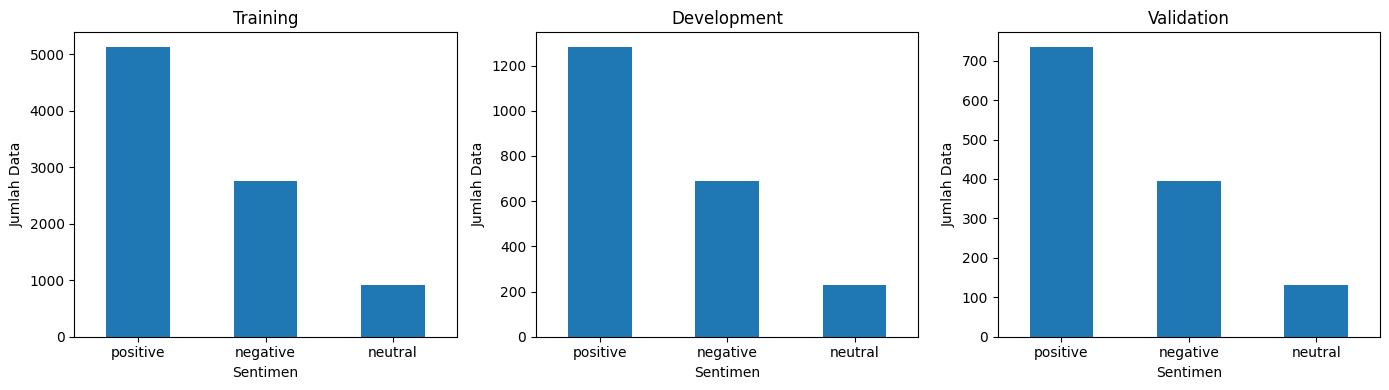


MISSING VALUE TRAINING
text     0
label    0
dtype: int64

MISSING VALUE VALIDATION
text     0
label    0
dtype: int64

DATA KOSONG ATAU SPASI
Training:
Text: 0
Label: 0
Validation:
Text: 0
Label: 0

Jumlah teks duplikat training: 67
Jumlah teks duplikat validation: 0

Contoh teks duplikat training:
                                                  text     label
9                                            bersyukur  positive
69                                               marah  negative
109  jangan pernah kecewa dengan apa yang diberikan...  positive
140  dasar gubernur tidak bermutu , pecat saja dari...  negative
166                 jokowi tidak suka sebar isu bohong  positive
266                                         berantakan  negative
344  maklum pak . sebelah pola fikir nya sempit . y...  negative
802  berkesempatan menikmati santap pagi dikarenaka...  positive
913  sudah lama dibaned , kalau pakai telkom dan te...  negative
948                                         bera

In [3]:
# 1. Jumlah data
print("JUMLAH DATA")
print("Training asli:", len(df_raw))
print("Training 80%:", len(df_train))
print("Development 20%:", len(df_dev))
print("Validation:", len(df_valid))
print("Total:", len(df_raw) + len(df_valid))

# 2. Distribusi kelas
print("\nDISTRIBUSI KELAS TRAINING")
print(df_train["label"].value_counts())
print("\nPersentase kelas pada data training:")
print((df_train["label"].value_counts(normalize=True) * 100).round(2))

print("\nDISTRIBUSI KELAS DEVELOPMENT")
print(df_dev["label"].value_counts())
print("\nPersentase kelas pada data develoment:")
print((df_dev["label"].value_counts(normalize=True) * 100).round(2))

print("\nDISTRIBUSI KELAS VALIDATION")
print(df_valid["label"].value_counts())
print("\nPersentase kelas pada data validation:")
print((df_valid["label"].value_counts(normalize=True) * 100).round(2))


# Grafik distribusi kelas
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

df_train["label"].value_counts().plot(kind="bar", ax=axes[0], title="Training")
df_dev["label"].value_counts().plot(kind="bar", ax=axes[1], title="Development")
df_valid["label"].value_counts().plot(kind="bar", ax=axes[2], title="Validation")

for ax in axes:
    ax.set_xlabel("Sentimen")
    ax.set_ylabel("Jumlah Data")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


# 3. Missing value
print("\nMISSING VALUE TRAINING")
print(df_raw.isnull().sum())

print("\nMISSING VALUE VALIDATION")
print(df_valid.isnull().sum())

print("\nDATA KOSONG ATAU SPASI")
print("Training:")
print("Text:", df_raw["text"].astype(str).str.strip().eq("").sum())
print("Label:", df_raw["label"].astype(str).str.strip().eq("").sum())
print("Validation:")
print("Text:", df_valid["text"].astype(str).str.strip().eq("").sum())
print("Label:", df_valid["label"].astype(str).str.strip().eq("").sum())

#Periksa data duplikat
print("\nJumlah teks duplikat training:", df_raw["text"].duplicated().sum())
print("Jumlah teks duplikat validation:", df_valid["text"].duplicated().sum())
print("\nContoh teks duplikat training:")
print(df_raw[df_raw["text"].duplicated(keep=False)].head(10))
print("\nContoh teks duplikat validation:")
print(df_valid[df_valid["text"].duplicated(keep=False)].head(10))

# Menghitung panjang teks
df_raw["panjang_teks"] = df_raw["text"].astype(str).apply(lambda x: len(x.split()))
df_valid["panjang_teks"] = df_valid["text"].astype(str).apply(lambda x: len(x.split()))
# Statistik panjang teks
print("\nSTATISTIK PANJANG TEKS TRAINING")
print(df_raw["panjang_teks"].describe())
print("\nSTATISTIK PANJANG TEKS VALIDATION")
print(df_valid["panjang_teks"].describe())

# Menampilkan 5 contoh teks dari setiap kelas
for label in ["positive", "negative", "neutral"]:
    print("\nKELAS:", label.upper())
    contoh = df_raw[df_raw["label"] == label]["text"].head(5)

    for i, teks in enumerate(contoh, 1):
        print(f"{i}. {teks}")


# Daftar kata yang akan diperiksa
kata_tidak_baku = ["gak", "nggak", "enggak", "aja", "banget","kayak", "udah", "kalo", "bgt"]
singkatan = ["yg", "dgn", "tdk", "utk", "krn", "dr"]
negasi = ["tidak", "bukan", "belum", "jangan", "tak"]
teks = df_raw["text"].astype(str).str.lower()

# Memeriksa kata tidak baku
print("\nKata tidak baku")
for kata in kata_tidak_baku:
    jumlah = teks.apply(lambda x: bool(re.search(r"\b" + kata + r"\b", x))).sum()
    if jumlah > 0:
        print(kata, ":", jumlah)
        
# Memeriksa singkatan
singkatan = ["yg", "dgn", "tdk", "utk", "krn", "dr"]
print("\nsingkatan")
for kata in singkatan:
    jumlah = teks.apply(
        lambda x: bool(re.search(r"\b" + kata + r"\b", x))
    ).sum()
print(kata, ":", jumlah)
print("\nkata negasi")
for kata in negasi:
    jumlah = teks.apply(lambda x: bool(re.search(r"\b" + kata + r"\b", x))).sum()
    if jumlah > 0:
        print(kata, ":", jumlah)
        
# Memeriksa beberapa kata bahasa Inggris
kata_inggris = ["good", "bad", "recommended", "service",
                "movie", "unboxing", "food", "wifi"]
print("\nKemungkinan code mixing")
for kata in kata_inggris:
    jumlah = teks.apply(
        lambda x: bool(re.search(r"\b" + kata + r"\b", x))
    ).sum()

    if jumlah > 0:
        print(kata, ":", jumlah)
print("\nJumlah teks yang mengandung tanda baca")
print(teks.apply(lambda x: bool(re.search(r"[.,!?;:]", x))).sum())
print("Jumlah teks yang mengandung emoticon")
print(teks.apply(lambda x: bool(re.search(r"[:;=]-?[)(D]|<3", x))).sum())

In [4]:
def minimal_preprocess(text):
    if not isinstance(text,str):
        return ""
    text= text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_train["text_baseline"] = df_train["text"].apply(minimal_preprocess)
df_dev["text_baseline"] = df_dev["text"].apply(minimal_preprocess)
for i in range(5):
    print("Sebelum :", df_train["text"].iloc[i])
    print("Sesudah :", df_train["text_baseline"].iloc[i])
    print()

Sebelum : tidak menyesal deh pakai bagus skin care hasil terpampang nyata tanpa bedak tanpa menguras :
Sesudah : tidak menyesal deh pakai bagus skin care hasil terpampang nyata tanpa bedak tanpa menguras :

Sebelum : makanan nya mostly adalah makanan barat , harga nya memang cukup menguras kantong . tapi memang restoran ini sangat romantis dengan pemandangan nya yang sangat indah di malam hari
Sesudah : makanan nya mostly adalah makanan barat , harga nya memang cukup menguras kantong . tapi memang restoran ini sangat romantis dengan pemandangan nya yang sangat indah di malam hari

Sebelum : kalau anda ingin makanan ringan sebagai camilan . dapur pasta menyediakan keperluan anda . enak pasta dan aneka makanan lainnya . kebetulan di kotabaru parahyangan juga ada , jadi sering menjadi tempat singgah makan mi tali . sangat yummy karena beberapa menu dipadukan dengan cita rasa nusantara .
Sesudah : kalau anda ingin makanan ringan sebagai camilan . dapur pasta menyediakan keperluan anda . en

In [62]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(ngram_range=(1, 1))
X_train = tfidf.fit_transform(df_train["text_baseline"])
X_dev = tfidf.transform(df_dev["text_baseline"])

y_train = df_train["label"]
y_dev = df_dev["label"]

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data development:", X_dev.shape[0])
print("Jumlah fitur TF-IDF:", len(tfidf.get_feature_names_out()))

from sklearn.linear_model import LogisticRegression
model_baseline = LogisticRegression(max_iter=1000,random_state=42)
model_baseline.fit(X_train, y_train)
pred_baseline = model_baseline.predict(X_dev)
print("\nModel Logistic Regression.")

Jumlah data training: 8800
Jumlah data development: 2200
Jumlah fitur TF-IDF: 15396

Model Logistic Regression.


In [63]:
hasil_semua = []
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

def simpan_hasil(
    tahap,
    nama,
    preprocessing,
    feature,
    classifier,
    y_true,
    y_pred
):
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    hasil_semua.append({
        "Tahap": tahap,
        "Eksperimen_Model": nama,
        "Preprocessing": preprocessing,
        "Feature": feature,
        "Classifier": classifier,
        "Accuracy": accuracy,
        "Macro-F1": macro_f1
    })

    print(f"{nama} berhasil dicatat.")

In [64]:
from sklearn.metrics import accuracy_score, classification_report, f1_score
hasil_semua = []
akurasi = accuracy_score(y_dev, pred_baseline)
print("HASIL EVALUASI BASELINE EXP-0")
print("Accuracy:", round(akurasi, 4))

print("\nClassification:")
print(classification_report( y_dev,pred_baseline,digits=4))

macro_f1 = f1_score( y_dev,pred_baseline,average="macro")
print("\nMacro-F1:", round(macro_f1, 4))

simpan_hasil(
    tahap="A",
    nama="EXP-0",
    preprocessing="Lowercase + Whitespace",
    feature="TF-IDF Unigram",
    classifier="Logistic Regression",
    y_true=y_dev,
    y_pred=pred_baseline
)

HASIL EVALUASI BASELINE EXP-0
Accuracy: 0.8745

Classification:
              precision    recall  f1-score   support

    negative     0.8093    0.8341    0.8215       687
     neutral     0.9244    0.6913    0.7910       230
    positive     0.9030    0.9291    0.9159      1283

    accuracy                         0.8745      2200
   macro avg     0.8789    0.8181    0.8428      2200
weighted avg     0.8760    0.8745    0.8734      2200


Macro-F1: 0.8428
EXP-0 berhasil dicatat.


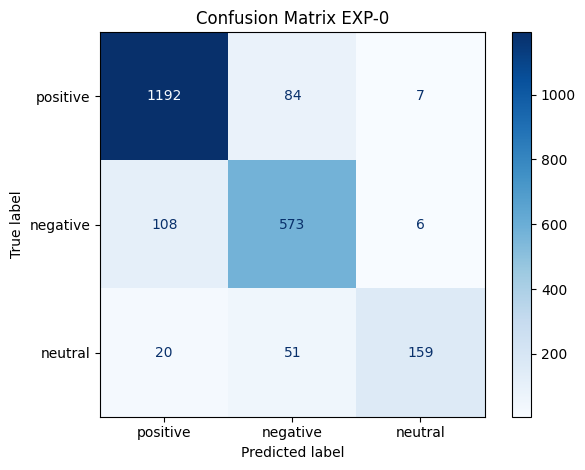


HASIL BASELINE EXP-0
  Experiment           Preprocessing         Feature           Classifier  \
0      EXP-0  Lowercase + Whitespace  TF-IDF Unigram  Logistic Regression   

   Accuracy  Macro-F1  
0  0.874545  0.842805  

CLASSIFICATION REPORT
              precision    recall  f1-score      support
negative       0.809322  0.834061  0.821505   687.000000
neutral        0.924419  0.691304  0.791045   230.000000
positive       0.903030  0.929072  0.915866  1283.000000
accuracy       0.874545  0.874545  0.874545     0.874545
macro avg      0.878924  0.818146  0.842805  2200.000000
weighted avg   0.876004  0.874545  0.873350  2200.000000

CONFUSION MATRIX
                   Predicted Positive  Predicted Negative  Predicted Neutral
Prediksi Positive                1192                  84                  7
Prediksi Negative                 108                 573                  6
Prediksi Neutral                   20                  51                159


In [65]:
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,classification_report)

cm = confusion_matrix(y_dev,pred_baseline,
    labels=["positive", "negative", "neutral"])

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
    display_labels=["positive", "negative", "neutral"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix EXP-0")
plt.tight_layout()
plt.show()

hasil_baseline = pd.DataFrame([{
    "Experiment": "EXP-0",
    "Preprocessing": "Lowercase + Whitespace",
    "Feature": "TF-IDF Unigram",
    "Classifier": "Logistic Regression",
    "Accuracy": akurasi,
    "Macro-F1": macro_f1}])
hasil_baseline.to_csv("EXP-0_results.csv", index=False)
print("\nHASIL BASELINE EXP-0")
print(hasil_baseline)

laporan = classification_report( y_dev,pred_baseline,output_dict=True,digits=4)
df_laporan = pd.DataFrame(laporan).transpose()
df_laporan.to_csv("EXP-0_metrics.csv")
print("\nCLASSIFICATION REPORT")
print(df_laporan)

df_cm = pd.DataFrame(cm,index=["Prediksi Positive", "Prediksi Negative", "Prediksi Neutral"],
    columns=[
        "Predicted Positive",
        "Predicted Negative",
        "Predicted Neutral" ])
df_cm.to_csv("EXP-0_confusion_matrix.csv")
print("\nCONFUSION MATRIX")
print(df_cm)


In [66]:
#normalisasi kata informal
normalisasi = {
    "gk": "tidak",
    "gak": "tidak",
    "nggak": "tidak",
    "enggak": "tidak",
    "tdk": "tidak",
    "bgt": "banget",
    "bgtt": "banget",
    "yg": "yang",
    "dgn": "dengan",
    "aja": "saja"
}
print("Jumlah normalisasi:", len(normalisasi))
for kata, hasil in normalisasi.items():
    print(kata, "->", hasil)

def normalisasi_teks(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    kata_list = text.split()

    kata_baru = [normalisasi.get(kata, kata)
        for kata in kata_list]
    text = " ".join(kata_baru)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_train["text_exp1"] = df_train["text"].apply(normalisasi_teks)
df_dev["text_exp1"] = df_dev["text"].apply(normalisasi_teks)
print("\nSEBELUM DAN SESUDAH NORMALISASI")
for i in range(5):
    print("Sebelum :", df_train["text"].iloc[i])
    print("Sesudah :", df_train["text_exp1"].iloc[i])


tfidf_exp1 = TfidfVectorizer(ngram_range=(1, 1))
X_train_exp1 = tfidf_exp1.fit_transform(df_train["text_exp1"])
X_dev_exp1 = tfidf_exp1.transform(df_dev["text_exp1"])
y_train = df_train["label"]
y_dev = df_dev["label"]
print("\nUkuran X_train:", X_train_exp1.shape)
print("Ukuran X_dev:", X_dev_exp1.shape)

model_exp1 = LogisticRegression(max_iter=1000,random_state=42)
model_exp1.fit(X_train_exp1, y_train)
pred_exp1 = model_exp1.predict(X_dev_exp1)
print("\nPelatihan EXP-1 ")

akurasi_exp1 = accuracy_score(y_dev, pred_exp1)
macro_f1_exp1 = f1_score(y_dev,pred_exp1,average="macro")
print("\nHASIL EVALUASI EXP-1")
print("Accuracy:", round(akurasi_exp1, 4))
print("Macro-F1:", round(macro_f1_exp1, 4))
print("\nClassification Report:")
print(classification_report(y_dev, pred_exp1, digits=4))

simpan_hasil(
    tahap="A",
    nama="EXP-1",
    preprocessing="Normalisasi Kata Informal",
    feature="TF-IDF Unigram",
    classifier="Logistic Regression",
    y_true=y_dev,
    y_pred=pred_exp1
)
df_results = pd.DataFrame(hasil_semua)
df_results.to_csv("results.csv", index=False)
print("\nSELURUH HASIL EKSPERIMEN")
display(df_results)
print("File results.csv berhasil diperbarui.")

Jumlah normalisasi: 10
gk -> tidak
gak -> tidak
nggak -> tidak
enggak -> tidak
tdk -> tidak
bgt -> banget
bgtt -> banget
yg -> yang
dgn -> dengan
aja -> saja

SEBELUM DAN SESUDAH NORMALISASI
Sebelum : tidak menyesal deh pakai bagus skin care hasil terpampang nyata tanpa bedak tanpa menguras :
Sesudah : tidak menyesal deh pakai bagus skin care hasil terpampang nyata tanpa bedak tanpa menguras :
Sebelum : makanan nya mostly adalah makanan barat , harga nya memang cukup menguras kantong . tapi memang restoran ini sangat romantis dengan pemandangan nya yang sangat indah di malam hari
Sesudah : makanan nya mostly adalah makanan barat , harga nya memang cukup menguras kantong . tapi memang restoran ini sangat romantis dengan pemandangan nya yang sangat indah di malam hari
Sebelum : kalau anda ingin makanan ringan sebagai camilan . dapur pasta menyediakan keperluan anda . enak pasta dan aneka makanan lainnya . kebetulan di kotabaru parahyangan juga ada , jadi sering menjadi tempat singgah mak

,Tahap,Eksperimen_Model,Preprocessing,Feature,Classifier,Accuracy,Macro-F1
0,A,EXP-0,Lowercase + Whitespace,TF-IDF Unigram,Logistic Regression,0.874545,0.842805
1,A,EXP-1,Normalisasi Kata Informal,TF-IDF Unigram,Logistic Regression,0.875000,0.843141


File results.csv berhasil diperbarui.


In [68]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
factory = StopWordRemoverFactory()
stopwords = set(factory.get_stop_words())

kata_negasi = ["tidak", "bukan", "belum", "jangan", "tak"]
stopwords = stopwords - set(kata_negasi)
print("Jumlah stopword:", len(stopwords))
print("Daftar stopword:", sorted(stopwords))
print("\nPEMERIKSAAN KATA NEGASI")
for kata in kata_negasi:
    print(kata, ":", kata not in stopwords)

def stopword_preprocess(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    words = text.split()
    words = [word for word in words if word not in stopwords]
    text = " ".join(words)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_train["text_exp2"] = df_train["text"].apply(stopword_preprocess)
df_dev["text_exp2"] = df_dev["text"].apply(stopword_preprocess)


print("\nSEBELUM DAN SESUDAH STOPWORD REMOVAL")
for i in range(5):
    print("\nSebelum :", df_train["text"].iloc[i])
    print("Sesudah :", df_train["text_exp2"].iloc[i])


tfidf_exp2 = TfidfVectorizer(ngram_range=(1, 1))
X_train_exp2 = tfidf_exp2.fit_transform(df_train["text_exp2"])
X_dev_exp2 = tfidf_exp2.transform(df_dev["text_exp2"])
print("\nUkuran X_train:", X_train_exp2.shape)
print("Ukuran X_dev:", X_dev_exp2.shape)

model_exp2 = LogisticRegression(max_iter=1000,random_state=42)
model_exp2.fit(X_train_exp2, y_train)
pred_exp2 = model_exp2.predict(X_dev_exp2)
print("\nPelatihan EXP-2 .")

akurasi_exp2 = accuracy_score(y_dev, pred_exp2)
macro_f1_exp2 = f1_score(y_dev, pred_exp2,average="macro")
print("\nHASIL EVALUASI EXP-2")
print("Accuracy:", round(akurasi_exp2, 4))
print("Macro-F1:", round(macro_f1_exp2, 4))
print("\nClassification Report:")
print(classification_report(y_dev, pred_exp2, digits=4))

simpan_hasil(
    tahap="A",
    nama="EXP-2",
    preprocessing="Normalisasi + Stopword Removal",
    feature="TF-IDF Unigram",
    classifier="Logistic Regression",
    y_true=y_dev,
    y_pred=pred_exp2
)

df_results = pd.DataFrame(hasil_semua)
df_results.to_csv("results.csv", index=False)
print("File results.csv berhasil diperbarui.")

Jumlah stopword: 121
Daftar stopword: ['ada', 'adalah', 'agak', 'agar', 'akan', 'amat', 'anda', 'antara', 'anu', 'apakah', 'apalagi', 'atau', 'bagaimanapun', 'bagi', 'bahwa', 'begitu', 'bisa', 'boleh', 'dahulu', 'dalam', 'dan', 'dapat', 'dari', 'daripada', 'demi', 'demikian', 'dengan', 'di', 'dia', 'dimana', 'dll', 'dsb', 'dst', 'dua', 'dulunya', 'guna', 'hal', 'hanya', 'harus', 'ia', 'ingin', 'ini', 'itu', 'itulah', 'jika', 'juga', 'kah', 'kami', 'karena', 'ke', 'kecuali', 'kemana', 'kembali', 'kenapa', 'kepada', 'ketika', 'kita', 'lagi', 'lain', 'maka', 'mari', 'masih', 'melainkan', 'mengapa', 'menurut', 'mereka', 'namun', 'nanti', 'nggak', 'oh', 'ok', 'oleh', 'pada', 'para', 'pasti', 'pula', 'pun', 'saat', 'saja', 'sambil', 'sampai', 'saya', 'sebab', 'sebagai', 'sebelum', 'sebetulnya', 'secara', 'sedangkan', 'seharusnya', 'sehingga', 'sekitar', 'selagi', 'selain', 'sementara', 'seolah', 'seperti', 'seraya', 'serta', 'sesuatu', 'sesudah', 'setelah', 'seterusnya', 'setiap', 'setidakny

In [69]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import time
factory_stemmer = StemmerFactory()
stemmer = factory_stemmer.create_stemmer()

print("Stemmer Sastrawi berhasil dibuat.")
def stemming_preprocess_optimized(series_text):
    print("\nMemulai ekstraksi kata unik...")
    waktu_mulai = time.time()
    all_words = set()
    for text in series_text:
        if isinstance(text, str):
            all_words.update(text.lower().split())
    stem_dict = {}
    total_kata = len(all_words)

    print(f"Total kata unik: {total_kata}")

    for idx, word in enumerate(all_words):
        stem_dict[word] = stemmer.stem(word)
        if (idx + 1) % 500 == 0:
            print(f"Progress: {idx + 1}/{total_kata} kata selesai")
    print(f"Stemming selesai dalam {time.time() - waktu_mulai:.2f} detik.")

    def transform_text(text):
        if not isinstance(text, str):
            return ""
        text = text.lower()
        text = re.sub(r'\s+', ' ', text).strip()
        kata_list = text.split()
        hasil_stemming = [stem_dict.get(kata, kata) for kata in kata_list]
        return " ".join(hasil_stemming)
    return series_text.apply(transform_text)


waktu_total_mulai = time.time()
gabungan_teks = pd.concat(
    [df_train["text"], df_dev["text"]],
    ignore_index=True
)

hasil_stemming = stemming_preprocess_optimized(gabungan_teks)
df_train["text_exp3"] = hasil_stemming.iloc[:len(df_train)].values
df_dev["text_exp3"] = hasil_stemming.iloc[len(df_train):].values


print("\nCONTOH SEBELUM DAN SESUDAH STEMMING")
for i in range(min(5, len(df_train))):
    print("\nSebelum :", df_train["text"].iloc[i])
    print("Sesudah :", df_train["text_exp3"].iloc[i])


tfidf_exp3 = TfidfVectorizer(ngram_range=(1, 1))
X_train_exp3 = tfidf_exp3.fit_transform(df_train["text_exp3"])
X_dev_exp3 = tfidf_exp3.transform(df_dev["text_exp3"])
print("\nUkuran X_train:", X_train_exp3.shape)
print("Ukuran X_dev:", X_dev_exp3.shape)


model_exp3 = LogisticRegression(max_iter=1000,random_state=42)
model_exp3.fit(X_train_exp3, y_train)
pred_exp3 = model_exp3.predict(X_dev_exp3)
print("\nPelatihan model EXP-3 selesai.")


akurasi_exp3 = accuracy_score(y_dev, pred_exp3)
macro_f1_exp3 = f1_score(y_dev, pred_exp3, average="macro")

print("\nHASIL EVALUASI EXP-3")
print(f"Accuracy : {akurasi_exp3:.4f}")
print(f"Macro-F1 : {macro_f1_exp3:.4f}")

print("\nClassification Report:")
print(classification_report(y_dev, pred_exp3, digits=4))

print(
    f"\nTotal waktu eksekusi: "
    f"{time.time() - waktu_total_mulai:.2f} detik."
)
simpan_hasil(
    "A", "EXP-3",
    "Normalisasi + Stemming",
    "TF-IDF Unigram",
    "Logistic Regression",
    y_dev, pred_exp3
)
pd.DataFrame(hasil_semua).to_csv("results.csv", index=False)

Stemmer Sastrawi berhasil dibuat.

Memulai ekstraksi kata unik...
Total kata unik: 18090
Progress: 500/18090 kata selesai
Progress: 1000/18090 kata selesai
Progress: 1500/18090 kata selesai
Progress: 2000/18090 kata selesai
Progress: 2500/18090 kata selesai
Progress: 3000/18090 kata selesai
Progress: 3500/18090 kata selesai
Progress: 4000/18090 kata selesai
Progress: 4500/18090 kata selesai
Progress: 5000/18090 kata selesai
Progress: 5500/18090 kata selesai
Progress: 6000/18090 kata selesai
Progress: 6500/18090 kata selesai
Progress: 7000/18090 kata selesai
Progress: 7500/18090 kata selesai
Progress: 8000/18090 kata selesai
Progress: 8500/18090 kata selesai
Progress: 9000/18090 kata selesai
Progress: 9500/18090 kata selesai
Progress: 10000/18090 kata selesai
Progress: 10500/18090 kata selesai
Progress: 11000/18090 kata selesai
Progress: 11500/18090 kata selesai
Progress: 12000/18090 kata selesai
Progress: 12500/18090 kata selesai
Progress: 13000/18090 kata selesai
Progress: 13500/18090

In [71]:
kata_negasi_exp4 = ["tidak", "bukan", "belum", "jangan", "tak"]
def negation_preprocess(text):
    if not isinstance(text, str):
        return ""

    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    for kata in kata_negasi_exp4:
        text = re.sub(
            r'\b' + kata + r'\s+(\w+)',
            kata + r'_\1',
            text
        )
    return text


df_train["text_exp4"] = df_train["text_exp1"].apply(negation_preprocess)
df_dev["text_exp4"] = df_dev["text_exp1"].apply(negation_preprocess)


print("SEBELUM DAN SESUDAH NORMALISASI + NEGATION HANDLING")

for i in range(5):
    print("\nTeks asli :", df_train["text"].iloc[i])
    print("Normalisasi :", df_train["text_exp1"].iloc[i])
    print("Hasil EXP-4 :", df_train["text_exp4"].iloc[i])


tfidf_exp4 = TfidfVectorizer(ngram_range=(1, 1))

X_train_exp4 = tfidf_exp4.fit_transform(df_train["text_exp4"])
X_dev_exp4 = tfidf_exp4.transform(df_dev["text_exp4"])

print("\nUkuran X_train:", X_train_exp4.shape)
print("Ukuran X_dev:", X_dev_exp4.shape)


model_exp4 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_exp4.fit(X_train_exp4, y_train)
pred_exp4 = model_exp4.predict(X_dev_exp4)


# Evaluasi
akurasi_exp4 = accuracy_score(y_dev, pred_exp4)
macro_f1_exp4 = f1_score(y_dev, pred_exp4, average="macro")

print("\nHASIL EVALUASI EXP-4")
print("Accuracy:", round(akurasi_exp4, 4))
print("Macro-F1:", round(macro_f1_exp4, 4))

print("\nClassification Report:")
print(classification_report(y_dev, pred_exp4, digits=4))

print(classification_report(y_dev, pred_exp4, digits=4))

simpan_hasil(
    "A", "EXP-4",
    "Normalisasi + Negation Handling",
    "TF-IDF Unigram",
    "Logistic Regression",
    y_dev, pred_exp4
)

pd.DataFrame(hasil_semua).to_csv("results.csv", index=False)

SEBELUM DAN SESUDAH NORMALISASI + NEGATION HANDLING

Teks asli : tidak menyesal deh pakai bagus skin care hasil terpampang nyata tanpa bedak tanpa menguras :
Normalisasi : tidak menyesal deh pakai bagus skin care hasil terpampang nyata tanpa bedak tanpa menguras :
Hasil EXP-4 : tidak_menyesal deh pakai bagus skin care hasil terpampang nyata tanpa bedak tanpa menguras :

Teks asli : makanan nya mostly adalah makanan barat , harga nya memang cukup menguras kantong . tapi memang restoran ini sangat romantis dengan pemandangan nya yang sangat indah di malam hari
Normalisasi : makanan nya mostly adalah makanan barat , harga nya memang cukup menguras kantong . tapi memang restoran ini sangat romantis dengan pemandangan nya yang sangat indah di malam hari
Hasil EXP-4 : makanan nya mostly adalah makanan barat , harga nya memang cukup menguras kantong . tapi memang restoran ini sangat romantis dengan pemandangan nya yang sangat indah di malam hari

Teks asli : kalau anda ingin makanan ringan se

In [74]:
#FEATURE ENRICHMENT N-GRAM
tfidf_unigram = TfidfVectorizer(ngram_range=(1, 1), max_features=50000)
X_train_unigram = tfidf_unigram.fit_transform(df_train["text_exp4"])
X_dev_unigram = tfidf_unigram.transform(df_dev["text_exp4"])

model_unigram = LogisticRegression(max_iter=1000,random_state=42)
model_unigram.fit(X_train_unigram, y_train)
pred_unigram = model_unigram.predict(X_dev_unigram)

akurasi_unigram = accuracy_score(y_dev, pred_unigram)
f1_unigram = f1_score(y_dev, pred_unigram, average="macro")

# Pengujian Unigram + Bigram
tfidf_bigram = TfidfVectorizer( ngram_range=(1, 2),max_features=50000)
X_train_bigram = tfidf_bigram.fit_transform(df_train["text_exp4"])
X_dev_bigram = tfidf_bigram.transform(df_dev["text_exp4"])

model_bigram = LogisticRegression(max_iter=1000,random_state=42)
model_bigram.fit(X_train_bigram, y_train)
pred_bigram = model_bigram.predict(X_dev_bigram)
akurasi_bigram = accuracy_score(y_dev, pred_bigram)
f1_bigram = f1_score(y_dev, pred_bigram, average="macro")

hasil_ngram = pd.DataFrame([
    {
        "Fitur": "TF-IDF Unigram",
        "Accuracy": akurasi_unigram,
        "Macro-F1": f1_unigram
    },
    {
        "Fitur": "TF-IDF Unigram + Bigram",
        "Accuracy": akurasi_bigram,
        "Macro-F1": f1_bigram
    }
])
display(hasil_ngram)


simpan_hasil(
    "A", "EXP-5 Unigram",
    "Normalisasi + Penanganan Negasi",
    "TF-IDF Unigram",
    "Logistic Regression",
    y_dev, pred_unigram
)

simpan_hasil(
    "A", "EXP-5 Bigram",
    "Normalisasi + Penanganan Negasi",
    "TF-IDF Unigram + Bigram",
    "Logistic Regression",
    y_dev, pred_bigram
)


df_hasil_semua = pd.DataFrame(hasil_semua)

df_hasil_semua.to_csv("results.csv", index=False)
print("\nSeluruh hasil eksperimen berhasil diperbarui.")

,Fitur,Accuracy,Macro-F1
0,TF-IDF Unigram,0.895,0.855282
1,TF-IDF Unigram + Bigram,0.890,0.842310


EXP-5 Unigram berhasil dicatat.
EXP-5 Bigram berhasil dicatat.

Seluruh hasil eksperimen berhasil diperbarui.


In [76]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import confusion_matrix


# Menggunakan teks hasil EXP-4
tfidf_final = TfidfVectorizer(ngram_range=(1, 1),max_features=50000)
X_train_final = tfidf_final.fit_transform(df_train["text_exp4"])
X_dev_final = tfidf_final.transform(df_dev["text_exp4"])
print("Ukuran X_train:", X_train_final.shape)
print("Ukuran X_dev:", X_dev_final.shape)

# M1 Multinomial Naive Bayes
model_nb = MultinomialNB(alpha=1.0)
model_nb.fit(X_train_final, y_train)
pred_nb = model_nb.predict(X_dev_final)

# M2 Logistic Regression
model_lr = LogisticRegression(max_iter=1000,random_state=42)
model_lr.fit(X_train_final, y_train)
pred_lr = model_lr.predict(X_dev_final)

# M3 - Linear SVM
model_svm = LinearSVC(C=1.0,random_state=42)
model_svm.fit(X_train_final, y_train)
pred_svm = model_svm.predict(X_dev_final)

hasil_model = pd.DataFrame([
    {
        "ID": "M1",
        "Classifier": "Multinomial Naive Bayes",
        "Accuracy": accuracy_score(y_dev, pred_nb),
        "Macro-F1": f1_score(
            y_dev, pred_nb, average="macro"
        )
    },
    {
        "ID": "M2",
        "Classifier": "Logistic Regression",
        "Accuracy": accuracy_score(y_dev, pred_lr),
        "Macro-F1": f1_score(
            y_dev, pred_lr, average="macro"
        )
    },
    {
        "ID": "M3",
        "Classifier": "Linear SVM",
        "Accuracy": accuracy_score(y_dev, pred_svm),
        "Macro-F1": f1_score(
            y_dev, pred_svm, average="macro"
        )
    }
])


display(hasil_model)

print("CLASSIFICATION REPORT - NAIVE BAYES")
print(classification_report(y_dev, pred_nb))

print("CLASSIFICATION REPORT - LOGISTIC REGRESSION")
print(classification_report(y_dev, pred_lr))

print("CLASSIFICATION REPORT - LINEAR SVM")
print(classification_report(y_dev, pred_svm))

simpan_hasil(
    "B", "M1",
    "Normalisasi + Penanganan Negasi",
    "TF-IDF Unigram",
    "Multinomial Naive Bayes",
    y_dev, pred_nb
)

simpan_hasil(
    "B", "M2",
    "Normalisasi + Penanganan Negasi",
    "TF-IDF Unigram",
    "Logistic Regression",
    y_dev, pred_lr
)

simpan_hasil(
    "B", "M3",
    "Normalisasi + Penanganan Negasi",
    "TF-IDF Unigram",
    "Linear SVM",
    y_dev, pred_svm
)

label_kelas = ["positive", "neutral", "negative"]
hasil_detail_model = []
daftar_model = [
    ("M1", "Multinomial Naive Bayes", pred_nb),
    ("M2", "Logistic Regression", pred_lr),
    ("M3", "Linear SVM", pred_svm)
]

for id_model, nama, prediksi in daftar_model:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_dev,
        prediksi,
        labels=label_kelas,
        zero_division=0
    )

    hasil_detail_model.append({
        "ID": id_model,
        "Classifier": nama,
        "Accuracy": accuracy_score(y_dev, prediksi),
        "Macro-F1": f1_score(y_dev, prediksi, average="macro"),

        "Precision Positive": precision[0],
        "Recall Positive": recall[0],
        "F1 Positive": f1[0],

        "Precision Neutral": precision[1],
        "Recall Neutral": recall[1],
        "F1 Neutral": f1[1],

        "Precision Negative": precision[2],
        "Recall Negative": recall[2],
        "F1 Negative": f1[2]
    })

hasil_detail_model = pd.DataFrame(hasil_detail_model)
display(hasil_detail_model.round(4))


print("CONFUSION MATRIX - M1 MULTINOMIAL NAIVE BAYES")
display(pd.DataFrame(
    confusion_matrix(y_dev, pred_nb, labels=label_kelas),
    index=["Actual Positive", "Actual Negative", "Actual Neutral"],
    columns=["Predicted Positive", "Predicted Negative", "Predicted Neutral"]))

print("CONFUSION MATRIX - M2 LOGISTIC REGRESSION")
display(pd.DataFrame(
    confusion_matrix(y_dev, pred_lr, labels=label_kelas),
    index=["Actual Positive", "Actual Negative", "Actual Neutral"],
    columns=["Predicted Positive", "Predicted Negative", "Predicted Neutral"]
))

print("CONFUSION MATRIX - M3 LINEAR SVM")
display(pd.DataFrame(
    confusion_matrix(y_dev, pred_svm, labels=label_kelas),
    index=["Actual Positive", "Actual Negative", "Actual Neutral"],
    columns=["Predicted Positive", "Predicted Negative", "Predicted Neutral"]
))
df_hasil_semua = pd.DataFrame(hasil_semua)
df_hasil_semua.to_csv("results.csv", index=False)
print("Semua hasil berhasil disimpan:")
print("results.csv")


Ukuran X_train: (8800, 16467)
Ukuran X_dev: (2200, 16467)


,ID,Classifier,Accuracy,Macro-F1
0,M1,Multinomial Naive Bayes,0.812273,0.666380
1,M2,Logistic Regression,0.895000,0.855282
2,M3,Linear SVM,0.906818,0.874847


CLASSIFICATION REPORT - NAIVE BAYES
              precision    recall  f1-score   support

    negative       0.80      0.71      0.75       687
     neutral       1.00      0.22      0.36       230
    positive       0.81      0.97      0.89      1283

    accuracy                           0.81      2200
   macro avg       0.87      0.63      0.67      2200
weighted avg       0.83      0.81      0.79      2200

CLASSIFICATION REPORT - LOGISTIC REGRESSION
              precision    recall  f1-score   support

    negative       0.83      0.89      0.86       687
     neutral       0.94      0.66      0.77       230
    positive       0.93      0.94      0.93      1283

    accuracy                           0.90      2200
   macro avg       0.90      0.83      0.86      2200
weighted avg       0.90      0.90      0.89      2200

CLASSIFICATION REPORT - LINEAR SVM
              precision    recall  f1-score   support

    negative       0.86      0.89      0.87       687
     neutral  

,ID,Classifier,Accuracy,Macro-F1,Precision Positive,Recall Positive,F1 Positive,Precision Neutral,Recall Neutral,F1 Neutral,Precision Negative,Recall Negative,F1 Negative
0,M1,Multinomial Naive Bayes,0.8123,0.6664,0.8116,0.9735,0.8852,1.0000,0.2217,0.3630,0.7984,0.7089,0.7510
1,M2,Logistic Regression,0.8950,0.8553,0.9257,0.9415,0.9335,0.9438,0.6565,0.7744,0.8299,0.8879,0.8579
2,M3,Linear SVM,0.9068,0.8748,0.9366,0.9439,0.9402,0.8821,0.7478,0.8094,0.8596,0.8908,0.8749


CONFUSION MATRIX - M1 MULTINOMIAL NAIVE BAYES


,Predicted Positive,Predicted Negative,Predicted Neutral
Actual Positive,1249,0,34
Actual Negative,90,51,89
Actual Neutral,200,0,487


CONFUSION MATRIX - M2 LOGISTIC REGRESSION


,Predicted Positive,Predicted Negative,Predicted Neutral
Actual Positive,1208,5,70
Actual Negative,24,151,55
Actual Neutral,73,4,610


CONFUSION MATRIX - M3 LINEAR SVM


,Predicted Positive,Predicted Negative,Predicted Neutral
Actual Positive,1211,9,63
Actual Negative,21,172,37
Actual Neutral,61,14,612


Semua hasil berhasil disimpan:
results.csv


In [39]:
df_error = pd.DataFrame({
    "Teks": df_dev["text"].values,
    "Label Sebenarnya": y_dev.values,
    "Naive Bayes": pred_nb,
    "Logistic Regression": pred_lr,
    "Linear SVM": pred_svm
})

# Mengambil data yang minimal salah diprediksi oleh satu classifier
df_error["NB Salah"] = df_error["Naive Bayes"] != df_error["Label Sebenarnya"]
df_error["LR Salah"] = df_error["Logistic Regression"] != df_error["Label Sebenarnya"]
df_error["SVM Salah"] = df_error["Linear SVM"] != df_error["Label Sebenarnya"]

data_error = df_error[
    df_error[["NB Salah", "LR Salah", "SVM Salah"]].any(axis=1)
]

# Mengambil 5 contoh error pertama
display(data_error[
    [
        "Teks",
        "Label Sebenarnya",
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM",
        "NB Salah",
        "LR Salah",
        "SVM Salah"
    ]
].head(5))

,Teks,Label Sebenarnya,Naive Bayes,Logistic Regression,Linear SVM,NB Salah,LR Salah,SVM Salah
17,saya dan keluarga mengunjungi paskal food pasa...,positive,positive,negative,positive,False,True,False
24,gue berharap semoga yang lagi menyinyirkan kor...,neutral,negative,negative,negative,True,True,True
28,tempat ini mengimingi makan steak dan daging d...,negative,positive,positive,negative,True,True,False
30,prabowo sama yenny saja ditolak . sabaar ya ro...,negative,positive,negative,negative,True,False,False
45,satu porsi isi 3 batagor . kalau rasa memang s...,positive,positive,negative,negative,False,True,True


In [53]:
idx = 0

raw_text = df_valid.iloc[idx]["text"]
teks_preprocessing = df_valid.iloc[idx]["text_exp4"]
label_asli = df_valid.iloc[idx]["label"]

print("\nteks asli:")
print(raw_text)
print("\nHasil Preprocessing:")
print(teks_preprocessing)
print("\nLabel sebenarnya:")
print(label_asli)

print("\nHASIL PREDIKSI MODEL")
prediksi_lr = model_lr.predict(X_valid_final[idx])[0]
prediksi_svm = model_svm.predict(X_valid_final[idx])[0]

print("Prediksi Logistic Regression:", prediksi_lr)
print("Prediksi Linear SVM:", prediksi_svm)


skor_lr = model_lr.decision_function(X_valid_final[idx])[0]
print("\nSkor Logistic Regression:")
for kelas, skor in zip(model_lr.classes_, skor_lr):
    print(kelas, ":", round(skor, 6))


skor_svm = model_svm.decision_function(X_valid_final[idx])[0]

print("\nSkor Linear SVM:")
for kelas, skor in zip(model_svm.classes_, skor_svm):
    print(kelas, ":", round(skor, 6))


idx_kelas = list(model_svm.classes_).index("negative")
bobot = model_svm.coef_[idx_kelas]

fitur = X_valid_final[idx]
nilai_tfidf = fitur.toarray()[0]

kontribusi = bobot * nilai_tfidf
nama_fitur = tfidf_final.get_feature_names_out()

hasil_fitur = pd.DataFrame({
    "Kata": nama_fitur,
    "TF-IDF (xi)": nilai_tfidf,
    "Bobot (wi)": bobot,
    "Kontribusi (wi*xi)": kontribusi
})

hasil_fitur = hasil_fitur[
    hasil_fitur["TF-IDF (xi)"] > 0
].sort_values(
    "Kontribusi (wi*xi)",
    ascending=False
)

print("\nLIMA KATA DENGAN KONTRIBUSI TERBESAR")
display(hasil_fitur.head(5).round(4))


teks asli:
meski masa kampanye sudah selesai , bukan berati habis pula upaya mengerek tingkat kedipilihan elektabilitas .

Hasil Preprocessing:
meski masa kampanye sudah selesai , bukan_berati habis pula upaya mengerek tingkat kedipilihan elektabilitas .

Label sebenarnya:
neutral

HASIL PREDIKSI MODEL
Prediksi Logistic Regression: negative
Prediksi Linear SVM: negative

Skor Logistic Regression:
negative : 0.779279
neutral : -0.19172
positive : -0.58756

Skor Linear SVM:
negative : 0.238958
neutral : -0.506452
positive : -0.873202

LIMA KATA DENGAN KONTRIBUSI TERBESAR


,Kata,TF-IDF (xi),Bobot (wi),Kontribusi (wi*xi)
12876,selesai,0.3110,0.9722,0.3023
6534,kampanye,0.3924,0.3080,0.1209
5357,habis,0.2623,0.4276,0.1122
8369,masa,0.2773,0.3891,0.1079
13692,sudah,0.1478,0.5150,0.0761


In [58]:
X_valid_final = tfidf_final.transform(df_valid["text_exp4"])
prediksi_final = model_svm.predict(X_valid_final)

df_error = pd.DataFrame({
    "Text": df_valid["text"].values,
    "Gold": df_valid["label"].values,
    "Prediction": prediksi_final
})

df_salah = df_error[
    df_error["Gold"] != df_error["Prediction"]
].copy()

jumlah_validasi = len(df_valid)
jumlah_salah = len(df_salah)
jumlah_benar = jumlah_validasi - jumlah_salah

error_rate = (jumlah_salah / jumlah_validasi) * 100

print("HASIL FINAL EVALUATION")
print("Jumlah data validation :", jumlah_validasi)
print("Prediksi benar          :", jumlah_benar)
print("Prediksi salah          :", jumlah_salah)
print("Error rate              :", round(error_rate, 2), "%")

df_10_error = df_salah.head(10).copy()
df_10_error.insert(
    0,
    "No",
    range(1, len(df_10_error) + 1)
)

df_10_error["Dugaan Penyebab"] = ""

# 7. Menampilkan 10 kesalahan prediksi
pd.set_option("display.max_colwidth", None)

print("\n10 CONTOH PREDIKSI SALAH")
display(df_10_error)

dugaan_penyebab = [
    "Ambiguous wording",       # Baris 1
    "Mixed sentiment",         # Baris 2
    "Sarkasme",                 # Baris 3
    "Domain-specific term",     # Baris 4
    "Mixed sentiment",         # Baris 5
    "Negasi",                   # Baris 6
    "Ambiguous wording",       # Baris 7
    "Kata informal/slang",     # Baris 8
    "Mixed sentiment",         # Baris 9
    "Label ambiguity"          # Baris 10
]

if len(df_10_error) == len(dugaan_penyebab):
    df_10_error["Dugaan Penyebab"] = dugaan_penyebab
else:
    print("Jumlah kategori harus disesuaikan dengan jumlah data error.")
print("TABEL ERROR ANALYSIS")
display(df_10_error)

df_kategori_error = (
    df_10_error["Dugaan Penyebab"]
    .value_counts()
    .reset_index()
)

df_kategori_error.columns = [
    "Kategori Error",
    "Jumlah"
]

print("JUMLAH SETIAP KATEGORI ERROR")
display(df_kategori_error)

HASIL FINAL EVALUATION
Jumlah data validation : 1260
Prediksi benar          : 1120
Prediksi salah          : 140
Error rate              : 11.11 %

10 CONTOH PREDIKSI SALAH


,No,Text,Gold,Prediction,Dugaan Penyebab
0,1,"meski masa kampanye sudah selesai , bukan berati habis pula upaya mengerek tingkat kedipilihan elektabilitas .",neutral,negative,
26,2,"kalau melihat desain nya pixel 3 sih biasa saja , tapi iklan nya ini bagus banget sampai bikin barang nya jadi terlihat wah banget",positive,negative,
64,3,fpi lagi kerja karena ketua nya perlu makan dan ongkos menginap ngekost di arab . lumayanlan bikin provikasi setiap hari dimedia memang pesanan nya begitu dari burung galak dan sapi dan aki-aki naif,negative,positive,
67,4,"bagi anda yang berasal dari jawa tengah , terutama solo dan yogya , mungkin akan cocok dengan rasa makanan yang disajikan di warung sunda ini . karena rasa makanan di warung mak une yang di depan taman pramuka , jalan riau , cenderung manis , layaknya makanan khas jawa solo dan yogya . bahkan sayur asam yang saya pesan pun , juga terasa manis . padahal , seharusnya sayur asam .",negative,positive,
84,5,"untuk kampung daun , tempat unik dan enak buat santai , tapi untuk makanan dan kebersihan sepertinya kurang . karena banyak sarang laba-laba , lalu kucing di mana . __sad__ saya takut kucing . jadi makan juga kurang nyaman .",positive,negative,
96,6,"bukan cuma jujur , edgar itu banyak dicintai masyarakat dan punya pendirian bagus .",positive,negative,
98,7,"orang yamg paling sulit dinasehati , kayak nya orang yang sedang jatuh cinta .",negative,positive,
109,8,harus era hukum nya teh mel . sing bisa kudu dibisa kebun . nomor hiji jagoan demokrat untuk jawa barat hiji .... !!!,positive,neutral,
118,9,"pas sudah niatan mau protes eh barang nya sampai , dan bagus . aku luluh mbak",positive,negative,
128,10,inna lillahi wa inna ilayhi raji un . kaget sekali mendengar kabar pak nusyirwan wakil walikota samarinda meninggal dunia .,neutral,negative,


TABEL ERROR ANALYSIS


,No,Text,Gold,Prediction,Dugaan Penyebab
0,1,"meski masa kampanye sudah selesai , bukan berati habis pula upaya mengerek tingkat kedipilihan elektabilitas .",neutral,negative,Ambiguous wording
26,2,"kalau melihat desain nya pixel 3 sih biasa saja , tapi iklan nya ini bagus banget sampai bikin barang nya jadi terlihat wah banget",positive,negative,Mixed sentiment
64,3,fpi lagi kerja karena ketua nya perlu makan dan ongkos menginap ngekost di arab . lumayanlan bikin provikasi setiap hari dimedia memang pesanan nya begitu dari burung galak dan sapi dan aki-aki naif,negative,positive,Sarkasme
67,4,"bagi anda yang berasal dari jawa tengah , terutama solo dan yogya , mungkin akan cocok dengan rasa makanan yang disajikan di warung sunda ini . karena rasa makanan di warung mak une yang di depan taman pramuka , jalan riau , cenderung manis , layaknya makanan khas jawa solo dan yogya . bahkan sayur asam yang saya pesan pun , juga terasa manis . padahal , seharusnya sayur asam .",negative,positive,Domain-specific term
84,5,"untuk kampung daun , tempat unik dan enak buat santai , tapi untuk makanan dan kebersihan sepertinya kurang . karena banyak sarang laba-laba , lalu kucing di mana . __sad__ saya takut kucing . jadi makan juga kurang nyaman .",positive,negative,Mixed sentiment
96,6,"bukan cuma jujur , edgar itu banyak dicintai masyarakat dan punya pendirian bagus .",positive,negative,Negasi
98,7,"orang yamg paling sulit dinasehati , kayak nya orang yang sedang jatuh cinta .",negative,positive,Ambiguous wording
109,8,harus era hukum nya teh mel . sing bisa kudu dibisa kebun . nomor hiji jagoan demokrat untuk jawa barat hiji .... !!!,positive,neutral,Kata informal/slang
118,9,"pas sudah niatan mau protes eh barang nya sampai , dan bagus . aku luluh mbak",positive,negative,Mixed sentiment
128,10,inna lillahi wa inna ilayhi raji un . kaget sekali mendengar kabar pak nusyirwan wakil walikota samarinda meninggal dunia .,neutral,negative,Label ambiguity


JUMLAH SETIAP KATEGORI ERROR


,Kategori Error,Jumlah
0,Mixed sentiment,3
1,Ambiguous wording,2
2,Sarkasme,1
3,Domain-specific term,1
4,Negasi,1
5,Kata informal/slang,1
6,Label ambiguity,1


In [59]:
df_bias = pd.DataFrame({
    "Text": df_valid["text"].to_numpy(),
    "Gold": df_valid["label"].to_numpy(),
    "Prediction": prediksi_final
})

df_bias["Panjang_Teks"] = df_bias["Text"].apply(
    lambda x: len(str(x).split())
)
batas_median = df_bias["Panjang_Teks"].median()
print("Median panjang teks:", batas_median)

df_bias["Subset_Panjang"] = df_bias["Panjang_Teks"].apply(
    lambda x: "Pendek" if x <= batas_median else "Panjang")
kata_negasi = ["tidak", "bukan", "belum", "jangan", "tak"]
pola_negasi = r"\b(" + "|".join(kata_negasi) + r")\b"
df_bias["Subset_Negasi"] = df_bias["Text"].apply(
    lambda x: "Dengan Negasi"
    if re.search(pola_negasi, str(x).lower())
    else "Tanpa Negasi")

def hitung_metrik(data, nama_subset):
    hasil = []

    for kategori in data[nama_subset].unique():
        subset = data[data[nama_subset] == kategori]

        macro_f1 = f1_score(
            subset["Gold"],
            subset["Prediction"],
            average="macro",
            zero_division=0
        )

        error_rate = (
            (subset["Gold"] != subset["Prediction"]).mean() * 100
        )

        hasil.append({
            "Kategori": kategori,
            "Jumlah Data": len(subset),
            "Macro-F1": round(macro_f1, 4),
            "Error Rate (%)": round(error_rate, 2)
        })

    return pd.DataFrame(hasil)


hasil_panjang = hitung_metrik(df_bias, "Subset_Panjang")
hasil_negasi = hitung_metrik(df_bias, "Subset_Negasi")

print("PERBANDINGAN TEKS PENDEK DAN PANJANG")
display(hasil_panjang)

print("PERBANDINGAN TEKS DENGAN DAN TANPA NEGASI")
display(hasil_negasi)

Median panjang teks: 28.0
PERBANDINGAN TEKS PENDEK DAN PANJANG


,Kategori,Jumlah Data,Macro-F1,Error Rate (%)
0,Pendek,647,0.8443,13.14
1,Panjang,613,0.7609,8.97


PERBANDINGAN TEKS DENGAN DAN TANPA NEGASI


,Kategori,Jumlah Data,Macro-F1,Error Rate (%)
0,Dengan Negasi,471,0.8087,12.10
1,Tanpa Negasi,789,0.8503,10.52
